# Debugging one EOD in detail (3-fish recording)

Set `ROW` (EOD row of the EOD table) and `PAIR` (the electrode pair to examine) below; the rest follows from them.

**Case:** row 17707, frame 25646 (`pair05_1_1.1cm_only_Denis_right_frame25646.png` in `examples_near_each_pair/`). Fish 0 (the emitter)
lies along the top wall with one end 1.1 cm from electrode 5−, the other fish ≥ 32 cm away. Both models predict pair 5 as the largest
pair, yet the recorded pair 5 is close to zero. Question: is electrode 5− on the **zero-potential line** of the fish's field (the
isopotential line where the potential is the same as far away; for a dipole, the line perpendicular to the body through its
electrical centre)?

Sections:
1. the EOD: tank, my midline vs SLEAP keypoints (which end is the head), where the pair's electrodes sit along the body;
2. the recording over the seconds around it: does the pair pass through zero, and with a sign change?
3. my model over the same EODs (cached voltages) and the head–tail direction of my midline in each frame;
4. the field of fish 0 for this EOD with the zero-potential line drawn, for my midline and for the SLEAP head–tail direction;
5. tests: head–tail direction, sink position, and moving the fish along its axis — what puts the zero line on the electrode?

Model throughout: BEM conductivities, other fish as bodies, fish 0 transparent, unit current, as in
`EOD_assignment_3_fish_conductivities.ipynb`; patterns × −1 (fixed sign) and scaled to max |v| = 1 when compared with the recording.

In [1]:
import os, pickle, hashlib, json
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mask_metrics as mm                         # ZEUS crop unpacking (sets the Agg backend...)
%matplotlib inline
import scipy.sparse as sp
from scipy.sparse.linalg import splu
from scipy.spatial import cKDTree
from compute_electric_field import (theta_outer, mask_to_grid, multipole_sources, build_multipole_b, occupancy_field, build_A_shell, solve_potential,
                                    unflatten_to_grid, gammas)
from midline_methods import fish_midline_with_head
from eod_assign import load_electrode_pairs, peak_pattern, pair_voltages, compare_patterns, model_cache_tag

DATA = 'data/3_fish_silent'
EOD_CSV = f'{DATA}/Assigned_Data_3fish_2024-10-15T14_12_25.csv'
TRACK_PKL = f'{DATA}/elephantnose_20241015T141225_tracking_final.pkl'
ELECTRODES_CSV = 'data/electrodes/electrodes_signed_px_coord_3-fish.csv'   # this recording's electrode file
QC = 'results/eod_ground_truth_3fish'                                      # outputs of EOD_assignment_3_fish_silent.ipynb
PREV_CACHE = f'{QC}/model_voltages_N150_sinks0and0.05_elc5c81b.pkl'          # its model voltages: previous set, 6,938 good-frame EODs
DENIS_CSV = 'results/eod_assignment_3_fish_silent/eod_assignment_summary.csv'   # Denis' latest run (3-fish electrodes, no refractory)
OUT = f'{QC}/conductivities'
os.makedirs(f'{OUT}/figures', exist_ok=True)

FISH, EMITTER = (0, 1, 2), 0                    # ZEUS labels: 1 = largest, 2 = second largest, 0 = smallest = the emitter
FISH_NAME = {0: 'fish 0 (smallest)', 1: 'fish 1 (largest)', 2: 'fish 2 (middle)'}
FISH_COLOR = {0: '#E0B000', 1: '#D45087', 2: '#2E8B57'}   # review-reel colours: yellow, pink, green
PX_PER_CM = 912 / 60                            # tank side: 912 px = 60 cm (Denis' pixel2cm)

# field model (as in EOD_assignment_3_fish_silent.ipynb)
N = 150                                         # tank grid resolution (N x N)
n_poles = 100                                   # n_poles + 1 point currents along each midline, tail -> head
h = 1.0 / (N - 1)                               # grid spacing (tank side = 1)
SINKS = (0.0, 0.05)                             # sink position: fraction of the body length from the tail tip
SINK_NAME = {0.0: 'sink at tail tip', 0.05: 'sink 5% from tail tip'}
CELL_CM = (912 - 1) / (N - 1) / PX_PER_CM       # grid spacing in cm: tank coords [0, 1] = P - 1 px
SKIN_CM = 0.005                                 # skin thickness of the BEM set (cm)
LAMBDA_CM = 1e-4 / 1e-3                         # CondMedio / CondPiel: the BEM skin costs as much as 0.1 cm of water
MATS = {                                        # conductivities relative to water (omega = 0, so eps plays no role)
    'previous': dict(sigma_water=1.0, eps_water=0.0, sigma_interior=200.0, eps_interior=0.0, sigma_skin=0.05, eps_skin=2.7e-6),
    'bem': dict(sigma_water=1.0,      eps_water=0.0,     # CondMedio 1e-4 S/cm -> reference
                sigma_interior=100.0, eps_interior=0.0,  # CondCuerpo 0.01 / 1e-4
                sigma_skin=1 / (LAMBDA_CM / SKIN_CM + 1 / 100.0), eps_skin=0.0),   # 0.04998: CondPiel 1e-3 S/cm^2 over SKIN_CM
}
DELTA_H = {'previous': 0.5, 'bem': SKIN_CM / CELL_CM}   # skin thickness in grid cells (bem: 0.0124)
MAT_NAME = {'previous': 'previous σ (interior 200, skin 0.05, 0.2 cm)', 'bem': 'BEM σ (interior 100, skin 0.05, 0.005 cm)'}
N_WORKERS = 5                                   # parallel field solves (the 2-fish run uses the other cores)

import subprocess
from matplotlib.lines import Line2D
import matplotlib.patheffects as pe

ROW, PAIR = 17707, 5                       # the EOD and the electrode pair to examine
WINDOW = 60                                # EODs before and after ROW for the time course
MAT = 'bem'
VIDEO = f'{DATA}/video2024-10-15T14_12_25.avi'
CACHE_BEM = f'{OUT}/model_voltages_N150_sinks0and0.05_elc5c81b_bem_a453a8.pkl'
DBG = f'{OUT}/debug_eod{ROW}'
os.makedirs(DBG, exist_ok=True)
C_MINE, C_DENIS, C_SLEAP, C_PAIR = '#1F5FBF', '#E8710A', '#00A6A6', '#C00000'
OUTLINE = [pe.withStroke(linewidth=3, foreground='k')]

In [2]:
df_eod = pd.read_csv(EOD_CSV)
trace_cols = {p: [c for c in df_eod.columns if c.startswith(f'electrode_{p}_t_')]
              for p in sorted({int(c.split('_')[1]) for c in df_eod.columns if c.startswith('electrode_')})}

def recorded_pair_traces(row, pair_ids):
    '''(n_pairs, n_samp) recorded voltages of one df_eod row, each pair demeaned.'''
    V = np.stack([row[trace_cols[p]].to_numpy(float) for p in pair_ids])
    return V - np.nanmean(V, axis=1, keepdims=True)

with open(TRACK_PKL, 'rb') as f:
    trk = pickle.load(f)
frames, P = trk['frames'], trk['shape'][0]

def frame_masks(k):
    '''(n_fish, P, P) full-frame bool masks of frame k, indexed by fish label (empty where a fish has no mask; remnants dropped).'''
    m = np.zeros((len(FISH), P, P), bool)
    fr = frames[k]
    for l, p, (y0, y1, x0, x1) in zip(fr['labels'], fr['masks'], fr['boxes']):
        if l in FISH: m[l, y0:y1, x0:x1] = mm.unpack_crop(p, (y0, y1, x0, x1))
    return m

pairs = load_electrode_pairs(ELECTRODES_CSV, P)        # [(pair id, + point, - point)] in (row, col) / (P - 1)
pair_ids = [pid for pid, _, _ in pairs]

with open(TRACK_PKL, 'rb') as f:
    fps = pickle.load(f)['fps']

def video_frame(k):
    '''Grayscale (P, P) frame k of the raw video (ffmpeg).'''
    out = subprocess.run(['ffmpeg', '-v', 'error', '-ss', f'{k / fps:.4f}', '-i', VIDEO, '-frames:v', '1', '-f', 'rawvideo',
                          '-pix_fmt', 'gray', '-'], capture_output=True, check=True).stdout
    return np.frombuffer(out, np.uint8).reshape(P, P)

def sleap_points(i, fish_letter='C'):
    '''SLEAP keypoints of Denis' fish (C = fish 0) in EOD row i: {name: (row, col) px}, mouth -> tail.'''
    return {kp: np.array([df_eod.loc[i, f'{kp}_y_{fish_letter}'], df_eod.loc[i, f'{kp}_x_{fish_letter}']])
            for kp in ('mouth', 'head', 'middle', 'tail')}

EL = {f'{pid}{s}': pt * (P - 1) for pid, pp, pm in pairs for s, pt in (('+', pp), ('−', pm))}   # electrode -> (row, col) px

In [3]:
def fish_midlines(fm):
    '''Midline (n_poles + 1, 2) in tank coords, tail -> head, of every fish; None where the mask is empty or the fit fails.'''
    out = []
    for m in fm:
        try:
            mid = fish_midline_with_head(m, n_ctrl=n_poles + 1)['midline'] if m.any() else None
            out.append(mid if mid is not None and np.isfinite(mid).all() else None)
        except Exception:
            out.append(None)
    return out

def build_A_fast(occ, N, delta_h, g_water, g_skin, g_interior):
    '''build_A_shell, vectorized: the same matrix, entry for entry (the per-edge weight _edge_weight and the diagonal summed in the
       same order: up, down, left, right neighbour).'''
    tx, ty = theta_outer(occ)
    gnode = np.where(occ > 0.5, g_interior, g_water).astype(complex)
    skin = delta_h * (1 / g_skin - 1 / g_interior)
    def w(gC, gM, thc):                                     # _edge_weight on arrays
        with np.errstate(invalid='ignore'):
            return np.where(np.isnan(thc), gC, 1.0 / (thc / gC + (1 - thc) / gM + skin))
    k = np.arange(N * N).reshape(N, N)                      # flatten_2d_grid: row-major
    W = {'up': w(gnode[1:, :], gnode[:-1, :], 1 - tx), 'down': w(gnode[:-1, :], gnode[1:, :], tx),
         'left': w(gnode[:, 1:], gnode[:, :-1], 1 - ty), 'right': w(gnode[:, :-1], gnode[:, 1:], ty)}
    src = {'up': k[1:, :], 'down': k[:-1, :], 'left': k[:, 1:], 'right': k[:, :-1]}
    dst = {'up': k[:-1, :], 'down': k[1:, :], 'left': k[:, :-1], 'right': k[:, 1:]}
    full = {d: np.zeros((N, N), complex) for d in W}        # each node's weight to each neighbour (0 where there is none)
    full['up'][1:, :], full['down'][:-1, :] = W['up'], W['down']
    full['left'][:, 1:], full['right'][:, :-1] = W['left'], W['right']
    ws = ((0j + full['up']) + full['down']) + full['left'] + full['right']
    r = np.concatenate([src[d].ravel() for d in W] + [k.ravel()])
    c = np.concatenate([dst[d].ravel() for d in W] + [k.ravel()])
    v = np.concatenate([W[d].ravel() for d in W] + [-ws.ravel()])
    return sp.coo_matrix((v, (r, c)), shape=(N * N, N * N), dtype=complex).tocsr()

def solve_sinks(A, bs, pin=0):
    '''solve_potential for several current layouts bs with one LU factorization (same pinned node and gauge); in real arithmetic
       when A is real (omega = 0).'''
    M = (-A).tocsr()
    if not np.any(M.imag.data): M = M.real
    keep = np.ones(M.shape[0]); keep[pin] = 0
    M = (sp.diags(keep) @ M + sp.csr_matrix(([1.0], ([pin], [pin])), shape=M.shape)).tocsc()
    lu = splu(M); out = []
    for b in bs:
        rhs = np.asarray(b).ravel(); rhs = (rhs.real if np.isrealobj(M.data) else rhs.astype(complex)).copy(); rhs[pin] = 0
        phi = lu.solve(rhs); out.append(phi - phi.mean())
    return out

GAM = {n: gammas(0.0, **m) for n, m in MATS.items()}

GB = gammas(0.0, **MATS[MAT])

def field(fm, mid, sink_frac=0.0):
    '''Potential (N, N) of fish 0 emitting unit current along `mid` (tail -> head, tank coords), the other fish as bodies.'''
    A = build_A_fast(occupancy_field(fm, N, skip=EMITTER), N, DELTA_H[MAT], *GB)
    b = build_multipole_b(*multipole_sources(mid, I0=1.0, sink_frac=sink_frac), h, N)
    return unflatten_to_grid(solve_sinks(A, [b])[0], N).real

def fields(fm, jobs):
    '''Several (midline, sink_frac) layouts for the same bodies, one LU factorization.'''
    A = build_A_fast(occupancy_field(fm, N, skip=EMITTER), N, DELTA_H[MAT], *GB)
    bs = [build_multipole_b(*multipole_sources(m, I0=1.0, sink_frac=s), h, N) for m, s in jobs]
    return [unflatten_to_grid(p, N).real for p in solve_sinks(A, bs)]

def pattern(v):
    '''Model pair voltages -> fixed-sign pattern (x -1, max |v| = 1).'''
    v = -np.asarray(v, float); return v / np.abs(v).max()

def head_agrees(mid, kpts):
    '''True if the head end of my midline (last point) is nearer SLEAP's mouth than its tail end is.'''
    m = mid * (P - 1)
    return np.linalg.norm(m[-1] - kpts['mouth']) < np.linalg.norm(m[0] - kpts['mouth'])

cache = pd.read_pickle(CACHE_BEM)
assert (cache.frame.to_numpy() == df_eod.Frame.to_numpy()).all()
jP = pair_ids.index(PAIR)

## 1. The EOD

Tank around fish 0: masks, my midline (blue, dot = head), SLEAP keypoints of fish 0 (teal: ▲ mouth, ● head, ■ middle, ▼ tail),
electrodes. The table gives, for each electrode within 15 cm of fish 0, the distance to the mask and where it sits along the body:
the fraction of body length from the tail **by SLEAP's head–tail direction** (0 = tail end, 1 = head end; < 0 or > 1 = beyond the
end) and the lateral offset from the midline.

row 17707, frame 25646, t = 512.92 s | my midline head end agrees with SLEAP's mouth: False
body length (my midline) 7.9 cm


/var/folders/w4/p225s7cd19n0j6tss7pdl21w0000gn/T/ipykernel_5233/1589367981.py:15: DeprecationWarning: Arrays of 2-dimensional vectors are deprecated. Use arrays of 3-dimensional vectors instead. (deprecated in NumPy 2.0)
  lateral = abs(np.cross(t, pt - m_px[j])) / PX_PER_CM


,to mask (cm),along body (tail 0 -> head 1),lateral (cm)
5−,1.06,-0.13,0.19
4+,3.13,-0.32,4.49
9−,3.68,-0.44,2.49
5+,13.78,2.28,9.37


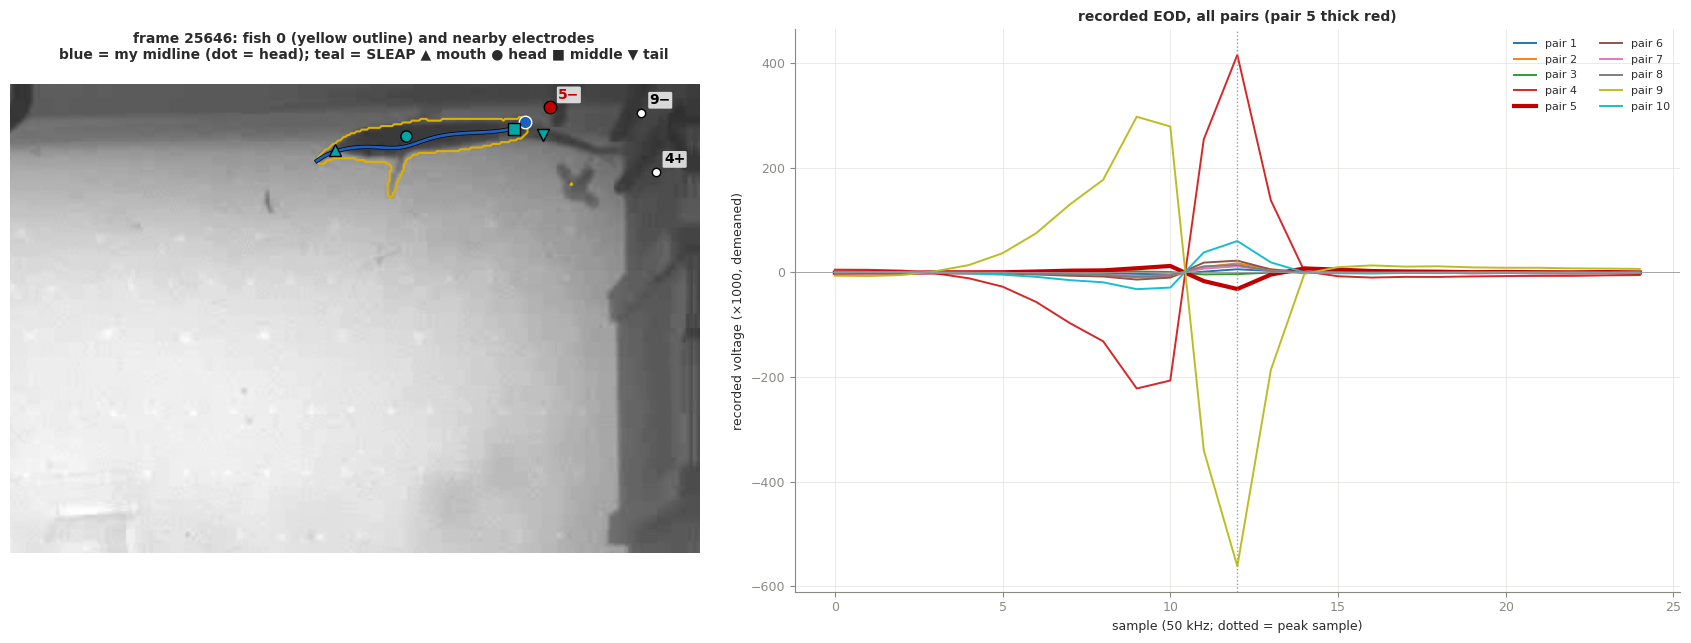

recorded peak pattern (max |v| = 1): {1: np.float64(0.011), 2: np.float64(0.031), 3: np.float64(-0.006), 4: np.float64(0.741), 5: np.float64(-0.056), 6: np.float64(0.04), 7: np.float64(0.021), 8: np.float64(0.025), 9: np.float64(-1.0), 10: np.float64(0.107)}


In [4]:
row = df_eod.loc[ROW]; K = int(row.Frame); fm = frame_masks(K); mids = fish_midlines(fm); kpts = sleap_points(ROW)
mid = mids[EMITTER]; agree = head_agrees(mid, kpts)
mid_sleap = mid if agree else mid[::-1]                                   # my midline with SLEAP's head-tail direction
print(f"row {ROW}, frame {K}, t = {row.RelativeTime:.2f} s | my midline head end agrees with SLEAP's mouth: {agree}")

m_px = mid_sleap * (P - 1); arc = np.r_[0, np.cumsum(np.linalg.norm(np.diff(m_px, axis=0), axis=1))]; L = arc[-1]
mask_pts = np.argwhere(fm[EMITTER])
rows = {}
for e, pt in EL.items():
    d_mask = np.linalg.norm(mask_pts - pt, axis=1).min() / PX_PER_CM
    if d_mask > 15: continue
    j = np.linalg.norm(m_px - pt, axis=1).argmin()
    t = m_px[min(j + 1, len(m_px) - 1)] - m_px[max(j - 1, 0)]; t = t / np.linalg.norm(t)
    along = arc[j] + (pt - m_px[j]) @ t                                    # beyond an end: extrapolated along the tangent
    lateral = abs(np.cross(t, pt - m_px[j])) / PX_PER_CM
    rows[e] = {'to mask (cm)': d_mask, 'along body (tail 0 -> head 1)': along / L, 'lateral (cm)': lateral}
geo = pd.DataFrame(rows).T.sort_values('to mask (cm)'); print(f'body length (my midline) {L / PX_PER_CM:.1f} cm'); display(geo.round(2))

V = recorded_pair_traces(row, pair_ids); r_rec, ts = peak_pattern(V); r_rec = r_rec / np.abs(r_rec).max()
img = video_frame(K)
c0 = mask_pts.mean(0); half = 230
fig, ax = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw=dict(width_ratios=[1, 1.25]))
a = ax[0]; a.imshow(img, cmap='gray')
for f in FISH:
    if fm[f].any(): a.contour(fm[f].astype(float), levels=[0.5], colors=[FISH_COLOR[f]], linewidths=1.5)
m = mid * (P - 1); a.plot(m[:, 1], m[:, 0], color=C_MINE, lw=2, path_effects=OUTLINE); a.plot(m[-1, 1], m[-1, 0], 'o', color=C_MINE, mec='w', ms=9)
for kp, mk in zip(kpts, ('^', 'o', 's', 'v')): a.plot(kpts[kp][1], kpts[kp][0], mk, color=C_SLEAP, mec='k', ms=8)
for e, pt in EL.items():
    hl = e.startswith(str(PAIR)) and len(e) == len(str(PAIR)) + 1
    a.plot(pt[1], pt[0], 'o', color=C_PAIR if hl else 'w', mec='k', ms=9 if hl else 6)
    a.annotate(e, pt[::-1], xytext=(6, 6), textcoords='offset points', fontsize=10, color=C_PAIR if hl else 'k', fontweight='bold',
               bbox=dict(boxstyle='round,pad=0.1', fc='w', ec='none', alpha=0.8))
a.set(xlim=(max(c0[1] - half, -10), min(c0[1] + half, P + 10)), ylim=(min(c0[0] + half, P + 10), max(c0[0] - half, -10)),
      title=f'frame {K}: fish 0 (yellow outline) and nearby electrodes\nblue = my midline (dot = head); teal = SLEAP ▲ mouth ● head ■ middle ▼ tail')
a.set_axis_off()
for j, pid in enumerate(pair_ids):
    ax[1].plot(V[j] * 1e3, lw=3 if pid == PAIR else 1.4, color=C_PAIR if pid == PAIR else plt.cm.tab10(j), label=f'pair {pid}')
ax[1].axhline(0, color='0.6', lw=0.6); ax[1].axvline(ts, color='0.6', ls=':', lw=1)
ax[1].set(xlabel='sample (50 kHz; dotted = peak sample)', ylabel='recorded voltage (×1000, demeaned)',
          title=f'recorded EOD, all pairs (pair {PAIR} thick red)')
ax[1].legend(ncol=2, fontsize=8)
plt.tight_layout(); fig.savefig(f'{DBG}/1_eod_and_geometry.png', dpi=110); plt.show()
print('recorded peak pattern (max |v| = 1):', dict(zip(pair_ids, r_rec.round(3))))

## 2. The recording over the seconds around this EOD

Signed peak-pattern value of every pair (max |v| = 1 per EOD), for the `WINDOW` EODs before and after (vertical line = this EOD).
If electrode 5− is near the zero-potential line, small movements of the fish move the line across the electrode: pair 5 should pass
through zero **and change sign**, while pairs whose electrodes are a few cm away (4+, 9− in the same corner) stay large. Below: SLEAP
position of fish 0's mouth and tail over the same EODs.

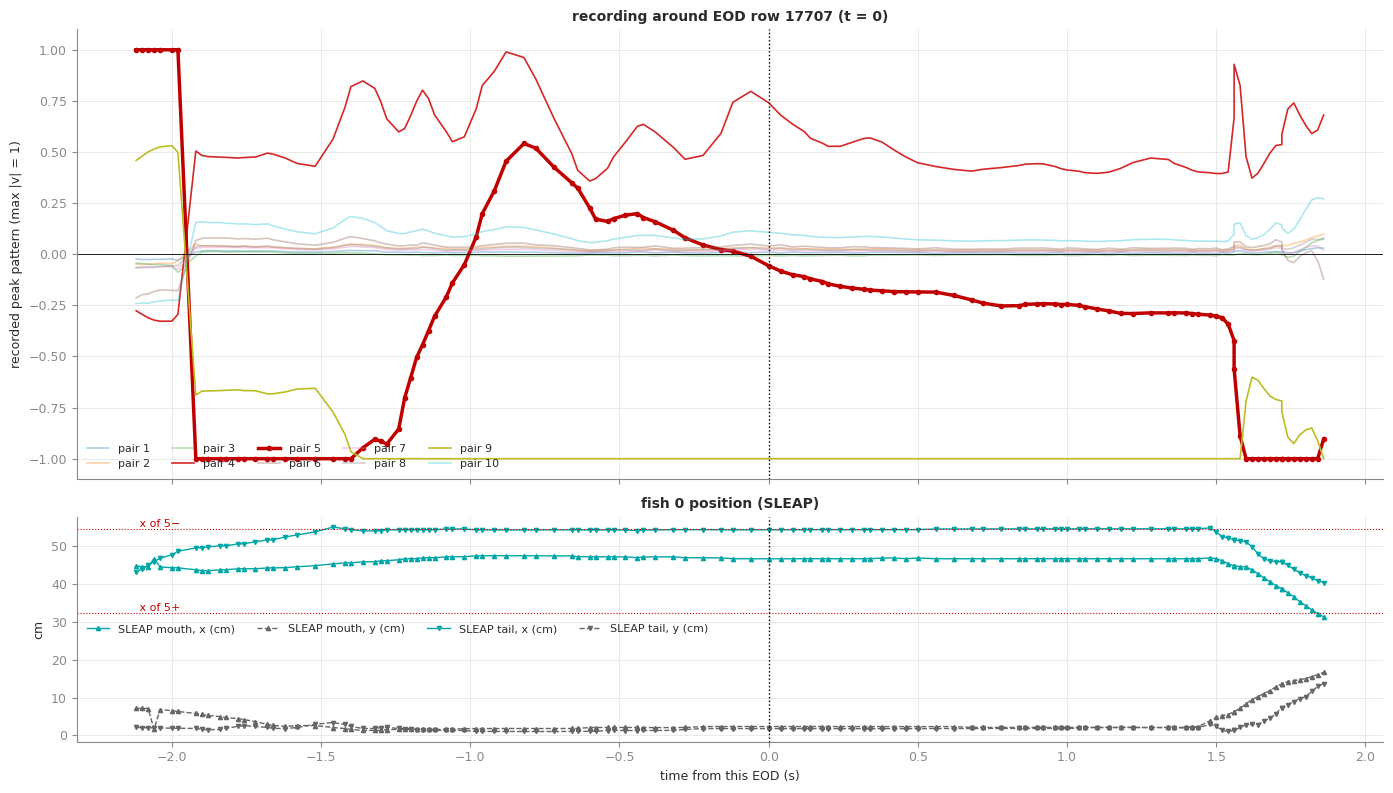

pair 5 changes sign 3 times in this window, at t = [-1.98 -1.02 -0.12] s


In [5]:
w = list(range(max(0, ROW - WINDOW), min(len(df_eod), ROW + WINDOW + 1)))
Rw = np.stack(cache.v_rec[w]); Rw = Rw / np.abs(Rw).max(1, keepdims=True)
Uw = np.stack(cache.u_sink0[w])[:, EMITTER]; Uw = -Uw / np.abs(Uw).max(1, keepdims=True)
tw = df_eod.RelativeTime[w].to_numpy(); t0 = row.RelativeTime
spw = [sleap_points(i) for i in w]

fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
for j, pid in enumerate(pair_ids):
    big = pid == PAIR or np.abs(Rw[:, j]).mean() > 0.2
    ax[0].plot(tw - t0, Rw[:, j], marker='o' if pid == PAIR else None, ms=3, lw=2.5 if pid == PAIR else 1.2,
               color=C_PAIR if pid == PAIR else plt.cm.tab10(j), alpha=1 if big else 0.35, label=f'pair {pid}')
ax[0].axhline(0, color='k', lw=0.6); ax[0].axvline(0, color='k', ls=':', lw=1)
ax[0].set(ylabel='recorded peak pattern (max |v| = 1)', title=f'recording around EOD row {ROW} (t = 0)')
ax[0].legend(ncol=5, fontsize=8, loc='lower left')
for kp, mk in (('mouth', '^'), ('tail', 'v')):
    p = np.stack([s[kp] for s in spw]) / PX_PER_CM
    ax[1].plot(tw - t0, p[:, 1], marker=mk, ms=3, lw=1, color=C_SLEAP, label=f'SLEAP {kp}, x (cm)')
    ax[1].plot(tw - t0, p[:, 0], marker=mk, ms=3, lw=1, ls='--', color='0.4', label=f'SLEAP {kp}, y (cm)')
for e in [k for k in EL if k.startswith(str(PAIR)) and len(k) == len(str(PAIR)) + 1]:
    ax[1].axhline(EL[e][1] / PX_PER_CM, color=C_PAIR, lw=0.8, ls=':'); ax[1].text(tw[0] - t0, EL[e][1] / PX_PER_CM, f' x of {e}', color=C_PAIR, va='bottom', fontsize=8)
ax[1].axvline(0, color='k', ls=':', lw=1)
ax[1].set(xlabel='time from this EOD (s)', ylabel='cm', title='fish 0 position (SLEAP)'); ax[1].legend(ncol=4, fontsize=8)
plt.tight_layout(); fig.savefig(f'{DBG}/2_recording_time_course.png', dpi=110); plt.show()

zc = np.flatnonzero(np.diff(np.sign(Rw[:, jP])) != 0)
print(f'pair {PAIR} changes sign {len(zc)} times in this window, at t =', np.round(tw[zc] - t0, 2), 's')

### Video frames at the extremes of pair 5

The EODs in the window where the recorded pair 5 is most negative, closest to zero (this EOD's neighbourhood) and most positive.

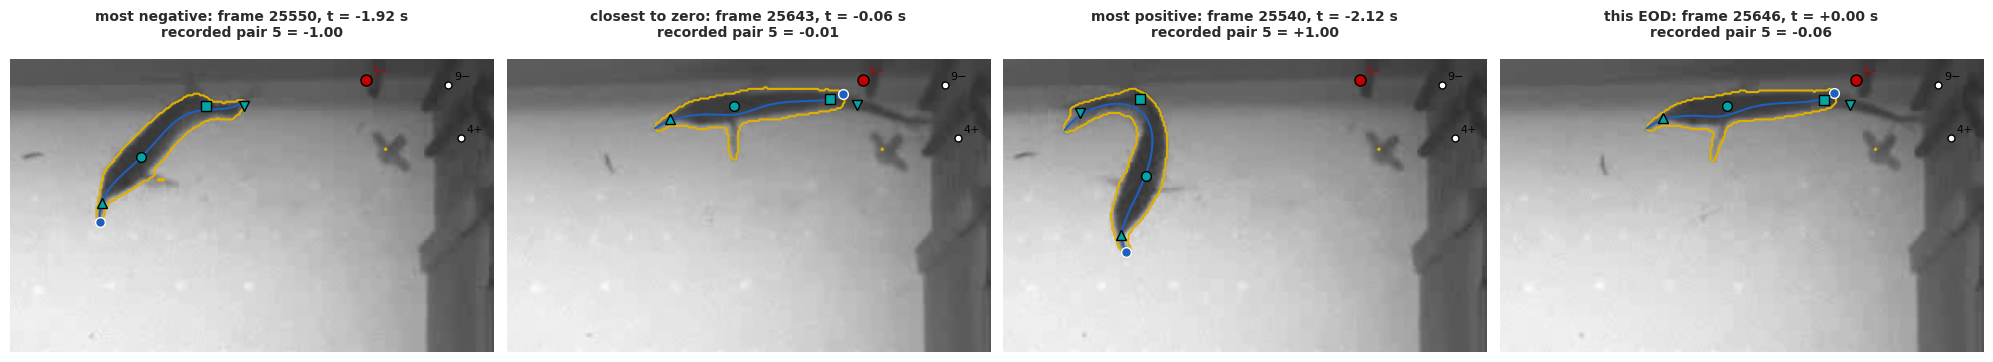

In [6]:
picks = {'most negative': w[int(Rw[:, jP].argmin())], 'closest to zero': w[int(np.abs(Rw[:, jP]).argmin())],
         'most positive': w[int(Rw[:, jP].argmax())], 'this EOD': ROW}
fig, ax = plt.subplots(1, len(picks), figsize=(5 * len(picks), 5))
for a, (nm, i) in zip(ax, picks.items()):
    k = int(df_eod.Frame[i]); fmi = frame_masks(k); mi = fish_midlines(fmi)[EMITTER]; spi = sleap_points(i)
    a.imshow(video_frame(k), cmap='gray')
    a.contour(fmi[EMITTER].astype(float), levels=[0.5], colors=[FISH_COLOR[EMITTER]], linewidths=1.5)
    if mi is not None:
        m = mi * (P - 1); a.plot(m[:, 1], m[:, 0], color=C_MINE, lw=1.5); a.plot(m[-1, 1], m[-1, 0], 'o', color=C_MINE, mec='w', ms=7)
    for kp, mk in zip(spi, ('^', 'o', 's', 'v')): a.plot(spi[kp][1], spi[kp][0], mk, color=C_SLEAP, mec='k', ms=7)
    for e, pt in EL.items():
        hl = e.startswith(str(PAIR)) and len(e) == len(str(PAIR)) + 1
        a.plot(pt[1], pt[0], 'o', color=C_PAIR if hl else 'w', mec='k', ms=8 if hl else 5)
        a.annotate(e, pt[::-1], xytext=(4, 4), textcoords='offset points', fontsize=8, color=C_PAIR if hl else 'k')
    a.set(xlim=(max(c0[1] - 150, -10), min(c0[1] + 150, P + 10)), ylim=(min(c0[0] + 150, P + 10), max(c0[0] - 150, -10)))
    a.set_title(f"{nm}: frame {k}, t = {df_eod.RelativeTime[i] - t0:+.2f} s\nrecorded pair {PAIR} = {Rw[w.index(i), jP]:+.2f}", fontsize=10)
    a.set_axis_off()
plt.tight_layout(); fig.savefig(f'{DBG}/2b_frames_pair_extremes.png', dpi=110); plt.show()

## 3. My model over the same EODs

Fixed-sign model pattern of fish 0 (cached voltages, BEM, sink at the tail tip) for pairs 4, 5 and 9, against the recording; markers
show whether my midline's head end agrees with SLEAP's mouth in that frame. A head–tail flip of the midline turns the whole pattern
upside down.

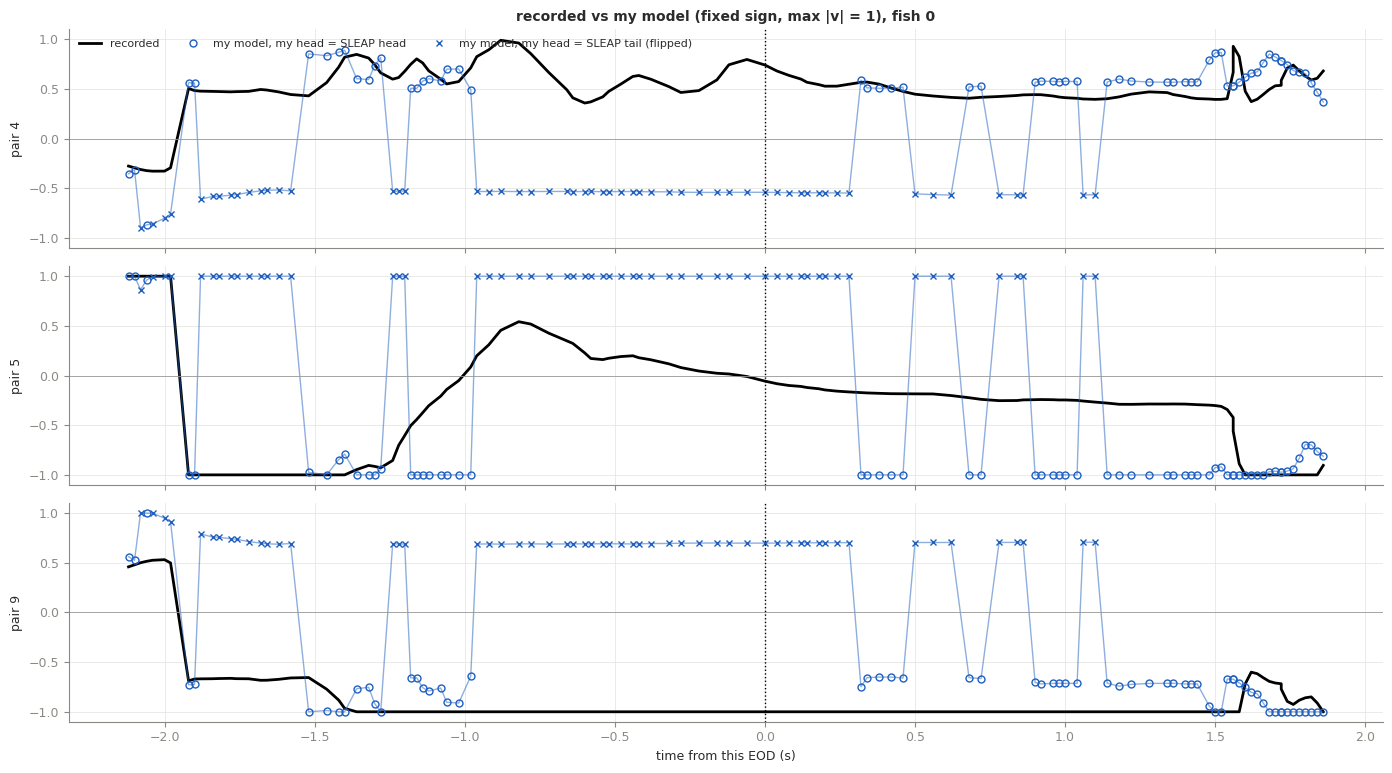

my midline agrees with SLEAP's head-tail direction in 54% of the 121 EODs


In [7]:
agree_w = []
for i in w:
    mi = fish_midlines(frame_masks(int(df_eod.Frame[i])))[EMITTER]
    agree_w.append(np.nan if mi is None else float(head_agrees(mi, sleap_points(i))))
agree_w = np.array(agree_w)

show = [p for p in pair_ids if p == PAIR or np.abs(Rw[:, pair_ids.index(p)]).mean() > 0.2]
fig, ax = plt.subplots(len(show), 1, figsize=(14, 2.6 * len(show)), sharex=True)
for a, p in zip(ax, show):
    j = pair_ids.index(p)
    a.plot(tw - t0, Rw[:, j], 'k-', lw=2, label='recorded')
    a.plot(tw - t0, Uw[:, j], '-', color=C_MINE, lw=1, alpha=0.5)
    for ok, mk, nm in ((1.0, 'o', 'my head = SLEAP head'), (0.0, 'x', 'my head = SLEAP tail (flipped)')):
        s = agree_w == ok
        a.plot((tw - t0)[s], Uw[s, j], mk, color=C_MINE, ms=5, mfc='none' if mk == 'o' else None, label=f'my model, {nm}')
    a.axhline(0, color='0.6', lw=0.6); a.axvline(0, color='k', ls=':', lw=1)
    a.set(ylabel=f'pair {p}', ylim=(-1.1, 1.1))
ax[0].legend(ncol=3, fontsize=8, loc='upper left'); ax[0].set_title('recorded vs my model (fixed sign, max |v| = 1), fish 0')
ax[-1].set_xlabel('time from this EOD (s)')
plt.tight_layout(); fig.savefig(f'{DBG}/3_model_time_course.png', dpi=110); plt.show()
print(f"my midline agrees with SLEAP's head-tail direction in {np.nanmean(agree_w) * 100:.0f}% of the {len(w)} EODs")

## 4. The field of fish 0 for this EOD

Potential of fish 0 emitting (unit current, sink at the tail tip, BEM). Colour: potential (red > 0, blue < 0; the tank mean is 0, which
is also the far-field level). Black line: **zero-potential line** (φ = 0). Dashed red line: the isopotential through electrode PAIR+,
i.e. where PAIR− would have to be for the pair to read zero (PAIR+ is far from the fish, so this line is close to the black one).
Left: my midline as fitted; right: my midline with SLEAP's head–tail direction.

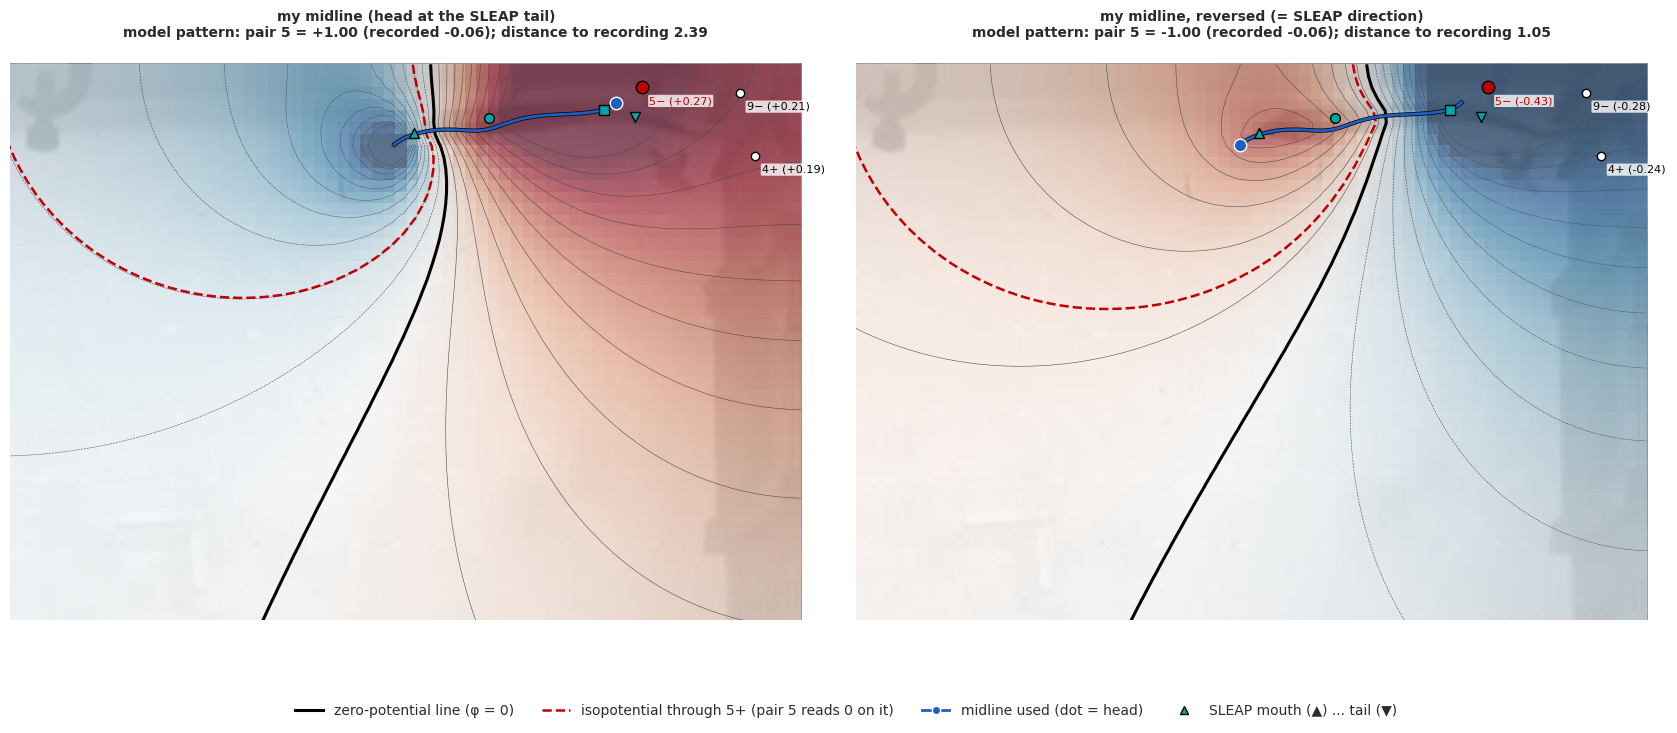

In [8]:
phi_mine, phi_sleap = fields(fm, [(mid, 0.0), (mid[::-1], 0.0)])
lay = {'my midline' + (' (= SLEAP direction)' if agree else ' (head at the SLEAP tail)'): phi_mine,
       'my midline, reversed' + (' (head at the SLEAP tail)' if agree else ' (= SLEAP direction)'): phi_sleap}
gpx = np.linspace(0, P - 1, N)
ep, em = EL[f'{PAIR}+'], EL[f'{PAIR}−']
def phi_at(phi, pt): return phi[tuple(np.round(pt / (P - 1) * (N - 1)).astype(int))]

fig, ax = plt.subplots(1, 2, figsize=(17, 7.5))
for a, (nm, phi) in zip(ax, lay.items()):
    v = np.percentile(np.abs(phi), 99.5)
    a.imshow(img, cmap='gray', alpha=0.6)
    a.imshow(phi, extent=[0, P - 1, P - 1, 0], cmap='RdBu_r', vmin=-v, vmax=v, alpha=0.55)
    a.contour(gpx, gpx, phi, levels=np.linspace(-v, v, 21), colors='0.3', linewidths=0.4)
    a.contour(gpx, gpx, phi, levels=[0], colors='k', linewidths=2.2)
    a.contour(gpx, gpx, phi, levels=[phi_at(phi, ep)], colors=C_PAIR, linewidths=1.8, linestyles='--')
    m = (mid if 'reversed' not in nm else mid[::-1]) * (P - 1)
    a.plot(m[:, 1], m[:, 0], color=C_MINE, lw=2, path_effects=OUTLINE); a.plot(m[-1, 1], m[-1, 0], 'o', color=C_MINE, mec='w', ms=9)
    for kp, mk in zip(kpts, ('^', 'o', 's', 'v')): a.plot(kpts[kp][1], kpts[kp][0], mk, color=C_SLEAP, mec='k', ms=7)
    for e, pt in EL.items():
        hl = e in (f'{PAIR}+', f'{PAIR}−')
        a.plot(pt[1], pt[0], 'o', color=C_PAIR if hl else 'w', mec='k', ms=9 if hl else 6)
        a.annotate(f'{e} ({phi_at(phi, pt):+.2f})', pt[::-1], xytext=(5, -12), textcoords='offset points', fontsize=8,
                   color=C_PAIR if hl else 'k', bbox=dict(boxstyle='round,pad=0.1', fc='w', ec='none', alpha=0.8))
    vm = pattern(pair_voltages(phi, pairs, N))
    a.set(xlim=(max(c0[1] - 260, -10), min(c0[1] + 260, P + 10)), ylim=(min(c0[0] + 260, P + 10), max(c0[0] - 260, -10)))
    a.set_title(f"{nm}\nmodel pattern: pair {PAIR} = {vm[jP]:+.2f} (recorded {r_rec[jP]:+.2f}); "
                f"distance to recording {np.linalg.norm(vm - r_rec):.2f}", fontsize=10)
    a.set_axis_off()
fig.legend(handles=[Line2D([], [], color='k', lw=2.2, label='zero-potential line (φ = 0)'),
                    Line2D([], [], color=C_PAIR, lw=1.8, ls='--', label=f'isopotential through {PAIR}+ (pair {PAIR} reads 0 on it)'),
                    Line2D([], [], color=C_MINE, lw=2, marker='o', mec='w', label='midline used (dot = head)'),
                    Line2D([], [], color=C_SLEAP, marker='^', ls='', mec='k', label='SLEAP mouth (▲) ... tail (▼)')],
           loc='lower center', ncol=4, fontsize=10, frameon=False, bbox_to_anchor=(0.5, -0.03))
plt.tight_layout(); fig.savefig(f'{DBG}/4_field_zero_line.png', dpi=110, bbox_inches='tight'); plt.show()

### Is the whole fish visible?

Body length of fish 0 in this EOD and in 300 random good-frame EODs (my mask midline, and SLEAP's mouth–head–middle–tail polyline).
A short fish here means part of the body is missing from the mask and the keypoints.

In [9]:
qc = pd.read_csv(f'{QC}/eod_qc_status.csv', index_col='row')
def body_lengths(i):
    '''(my midline length, SLEAP polyline length) of fish 0 in EOD row i, cm.'''
    m = fish_midlines(frame_masks(int(df_eod.Frame[i])))[EMITTER]; k = sleap_points(i)
    sl = sum(np.linalg.norm(k[b] - k[a]) for a, b in (('mouth', 'head'), ('head', 'middle'), ('middle', 'tail')))
    return (np.nan if m is None else np.linalg.norm(np.diff(m * (P - 1), axis=0), axis=1).sum() / PX_PER_CM), sl / PX_PER_CM
smp = np.random.default_rng(0).choice(np.flatnonzero(qc.analysed.to_numpy()), 300, replace=False)
Ls = np.array([body_lengths(i) for i in smp])
display(pd.DataFrame({'this EOD': body_lengths(ROW), 'good frames, 10th pct': np.nanpercentile(Ls, 10, axis=0),
                      'good frames, median': np.nanpercentile(Ls, 50, axis=0), 'good frames, 90th pct': np.nanpercentile(Ls, 90, axis=0)},
                     index=['my mask midline (cm)', 'SLEAP polyline (cm)']).round(1))

,this EOD,"good frames, 10th pct","good frames, median","good frames, 90th pct"
my mask midline (cm),7.9,10.5,11.6,12.0
SLEAP polyline (cm),7.7,8.5,9.8,10.2


## 5. What would put the zero line on the electrode?

With SLEAP's head–tail direction, fish 0's model pattern as one thing is changed at a time:
- **sink position**: the single sink moved from the tail tip (0) towards the head (fraction of body length); the sources stay spread
  along the rest of the body (`multipole_sources`);
- **position along the body axis**: the whole midline moved along its tail→head chord, −3 to +3 cm (the other fish stay put);
- **a longer fish**: the midline extended straight beyond its tail end (solid) or its head end (dashed) by 0–4 cm, as if that part
  of the body were missing from the mask (sink at the new tail tip); where the straight extension would reach the wall it runs along
  the wall, 0.5 cm inside.

Top: pattern values of the large pairs and of PAIR, with the recorded values as horizontal lines. Bottom: distance between fish 0's
pattern and the recording, with fish 1's and fish 2's distances for this EOD (cached, unchanged) as horizontal lines: fish 0 wins below
both.

midlines leaving the tank (not plotted): []


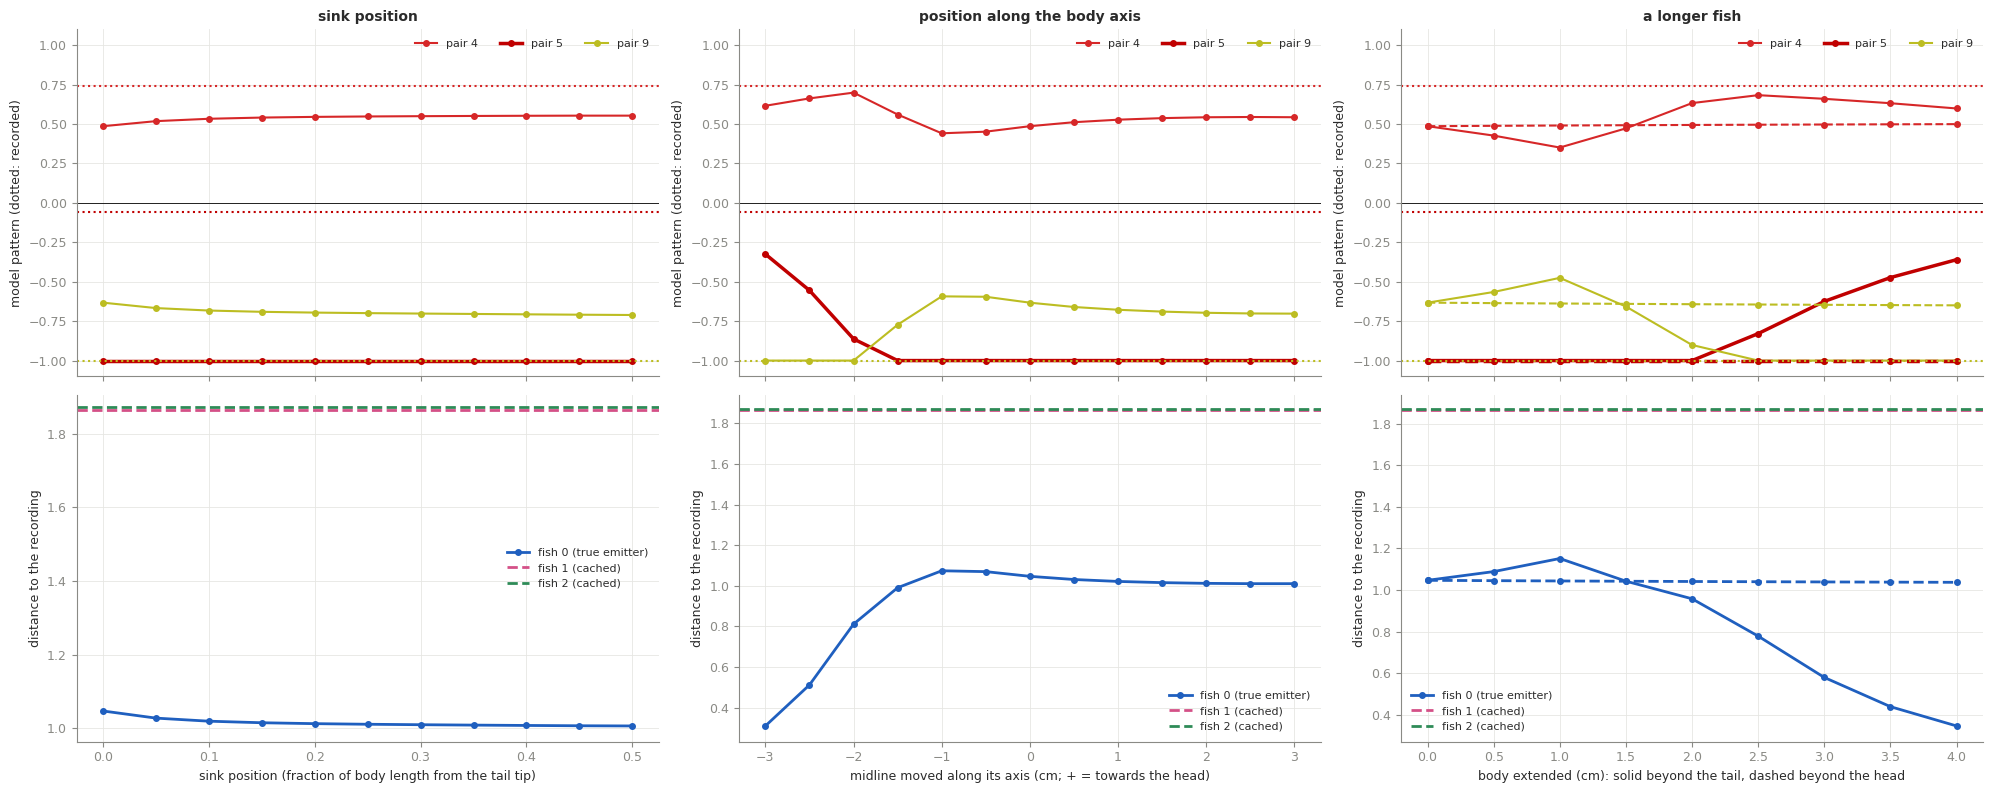

,pair 4,pair 5,pair 9,distance
sink frac,,,,
0.00,0.49,-1.0,-0.63,1.05
0.05,0.52,-1.0,-0.67,1.03
0.10,0.53,-1.0,-0.68,1.02
0.15,0.54,-1.0,-0.69,1.01
0.20,0.54,-1.0,-0.70,1.01
0.25,0.55,-1.0,-0.70,1.01
0.30,0.55,-1.0,-0.70,1.01
0.35,0.55,-1.0,-0.70,1.01
0.40,0.55,-1.0,-0.71,1.01


,pair 4,pair 5,pair 9,distance
shift (cm),,,,
-3.0,0.62,-0.32,-1.00,0.31
-2.5,0.66,-0.56,-1.00,0.51
-2.0,0.70,-0.86,-1.00,0.81
-1.5,0.56,-1.00,-0.77,0.99
-1.0,0.44,-1.00,-0.59,1.07
-0.5,0.45,-1.00,-0.60,1.07
0.0,0.49,-1.00,-0.63,1.05
0.5,0.51,-1.00,-0.66,1.03
1.0,0.53,-1.00,-0.68,1.02


,pair 4,pair 5,pair 9,distance
extended beyond the tail (cm),,,,
0.0,0.49,-1.00,-0.63,1.05
0.5,0.43,-1.00,-0.57,1.09
1.0,0.35,-1.00,-0.48,1.15
1.5,0.47,-1.00,-0.66,1.04
2.0,0.63,-1.00,-0.90,0.96
2.5,0.68,-0.83,-1.00,0.78
3.0,0.66,-0.62,-1.00,0.58
3.5,0.63,-0.47,-1.00,0.44
4.0,0.60,-0.36,-1.00,0.35


,pair 4,pair 5,pair 9,distance
extended beyond the head (cm),,,,
0.0,0.49,-1.0,-0.63,1.05
0.5,0.49,-1.0,-0.64,1.04
1.0,0.49,-1.0,-0.64,1.04
1.5,0.49,-1.0,-0.64,1.04
2.0,0.49,-1.0,-0.64,1.04
2.5,0.50,-1.0,-0.64,1.04
3.0,0.50,-1.0,-0.65,1.04
3.5,0.50,-1.0,-0.65,1.04
4.0,0.50,-1.0,-0.65,1.04


recorded: {'pair 4': 0.74, 'pair 5': -0.06, 'pair 9': -1.0} | fish 1, 2 distances: {1: 1.86, 2: 1.87}


In [10]:
base = mid_sleap
SINK_GRID = np.round(np.linspace(0, 0.5, 11), 2)
chord = (base[-1] - base[0]) / np.linalg.norm(base[-1] - base[0])
SHIFT_CM = np.linspace(-3, 3, 13)
shift_t = SHIFT_CM * PX_PER_CM / (P - 1)                                     # cm -> tank coords
EXT_CM = np.linspace(0, 4, 9)

def extend(m, cm, end):
    '''Midline m (tail -> head, tank coords) extended straight by `cm` beyond its tail or head end (kept >= 0.5 cm inside the walls,
       so near a wall it runs along it), resampled to the same number of points evenly along its length.'''
    m = m if end == 'tail' else m[::-1]
    t = m[0] - m[min(5, len(m) - 1)]; t = t / np.linalg.norm(t)
    lo = 0.5 * PX_PER_CM / (P - 1)
    ext = np.clip(m[0] + np.linspace(0, 1, 20)[1:, None] * t * cm * PX_PER_CM / (P - 1), lo, 1 - lo)[::-1]
    a = np.r_[0, np.cumsum(np.linalg.norm(np.diff(np.vstack([ext, m[:1]]), axis=0), axis=1))]
    keep = a[-1] - a[:-1] <= cm * PX_PER_CM / (P - 1) + 1e-12                       # the clipped path, cut to `cm` of length
    e = np.vstack([ext[keep], m]) if cm > 0 else m
    a = np.r_[0, np.cumsum(np.linalg.norm(np.diff(e, axis=0), axis=1))]; u = np.linspace(0, a[-1], len(m))
    e = np.stack([np.interp(u, a, e[:, 0]), np.interp(u, a, e[:, 1])], axis=1)
    return e if end == 'tail' else e[::-1]

jobs = ([(base, s) for s in SINK_GRID] + [(base + d * chord, 0.0) for d in shift_t] +
        [(extend(base, e, 'tail'), 0.0) for e in EXT_CM] + [(extend(base, e, 'head'), 0.0) for e in EXT_CM])
inside = np.array([((m >= 0) & (m <= 1)).all() for m, _ in jobs])                # a midline leaving the tank is not valid
pats = np.stack([pattern(pair_voltages(p, pairs, N)) for p in fields(fm, jobs)]); pats[~inside] = np.nan
n1, n2, n3 = len(SINK_GRID), len(SINK_GRID) + len(SHIFT_CM), len(SINK_GRID) + len(SHIFT_CM) + len(EXT_CM)
pat_sink, pat_shift, pat_tail, pat_head = pats[:n1], pats[n1:n2], pats[n2:n3], pats[n3:]
print('midlines leaving the tank (not plotted):', [f'tail +{e:g} cm' for e, ok in zip(EXT_CM, inside[n2:n3]) if not ok] +
      [f'head +{e:g} cm' for e, ok in zip(EXT_CM, inside[n3:]) if not ok] + [f'shift {d:+g} cm' for d, ok in zip(SHIFT_CM, inside[n1:n2]) if not ok])

Uc = -np.stack(cache.u_sink0[[ROW]])[0]; Uc = Uc / np.abs(Uc).max(1, keepdims=True)
d_other = {f: np.linalg.norm(Uc[f] - r_rec) for f in FISH if f != EMITTER}
big = [p for p in pair_ids if abs(r_rec[pair_ids.index(p)]) > 0.2 or p == PAIR]

panels = [(SINK_GRID, [(pat_sink, '-')], 'sink position (fraction of body length from the tail tip)', 'sink position'),
          (SHIFT_CM, [(pat_shift, '-')], 'midline moved along its axis (cm; + = towards the head)', 'position along the body axis'),
          (EXT_CM, [(pat_tail, '-'), (pat_head, '--')], 'body extended (cm): solid beyond the tail, dashed beyond the head',
           'a longer fish')]
fig, ax = plt.subplots(2, 3, figsize=(20, 8), sharex='col')
for col, (x, curves, xl, title) in enumerate(panels):
    for pats_, ls in curves:
        for p in big:
            j = pair_ids.index(p); c = C_PAIR if p == PAIR else plt.cm.tab10(j)
            ax[0, col].plot(x, pats_[:, j], 'o', ls=ls, color=c, lw=2.5 if p == PAIR else 1.5, ms=4,
                            label=f'pair {p}' if ls == '-' else None)
        ax[1, col].plot(x, np.linalg.norm(pats_ - r_rec, axis=1), 'o', ls=ls, color=C_MINE, lw=2, ms=4,
                        label='fish 0 (true emitter)' if ls == '-' else None)
    for p in big:
        j = pair_ids.index(p); ax[0, col].axhline(r_rec[j], color=C_PAIR if p == PAIR else plt.cm.tab10(j), ls=':', lw=1.5)
    ax[0, col].axhline(0, color='k', lw=0.6); ax[0, col].set(ylabel='model pattern (dotted: recorded)', ylim=(-1.1, 1.1), title=title)
    ax[0, col].legend(fontsize=8, ncol=len(big))
    for f, d in d_other.items(): ax[1, col].axhline(d, color=FISH_COLOR[f], lw=2, ls='--', label=f'fish {f} (cached)')
    ax[1, col].set(xlabel=xl, ylabel='distance to the recording'); ax[1, col].legend(fontsize=8)
plt.tight_layout(); fig.savefig(f'{DBG}/5_tests.png', dpi=110); plt.show()
display(pd.DataFrame(pat_sink[:, [pair_ids.index(p) for p in big]], index=pd.Index(SINK_GRID, name='sink frac'),
                     columns=[f'pair {p}' for p in big]).assign(distance=np.linalg.norm(pat_sink - r_rec, axis=1)).round(2))
display(pd.DataFrame(pat_shift[:, [pair_ids.index(p) for p in big]], index=pd.Index(SHIFT_CM.round(1), name='shift (cm)'),
                     columns=[f'pair {p}' for p in big]).assign(distance=np.linalg.norm(pat_shift - r_rec, axis=1)).round(2))
for nm, pp_ in (('tail', pat_tail), ('head', pat_head)):
    display(pd.DataFrame(pp_[:, [pair_ids.index(p) for p in big]], index=pd.Index(EXT_CM, name=f'extended beyond the {nm} (cm)'),
                         columns=[f'pair {p}' for p in big]).assign(distance=np.linalg.norm(pp_ - r_rec, axis=1)).round(2))
print('recorded:', {f'pair {p}': round(float(r_rec[pair_ids.index(p)]), 2) for p in big}, '| fish 1, 2 distances:',
      {f: round(float(d), 2) for f, d in d_other.items()})

## 6. Findings (row 17707, frame 25646, pair 5)

**Why this EOD went to the wrong fish: my midline has the head at the wrong end.** My midline puts fish 0's head next to electrode 5−;
SLEAP puts the tail there. Over the 121 EODs around it (5 s, fish lying still along the wall) my midline agrees with SLEAP's head–tail
direction in only 54% of EODs, and my model pattern flips sign with it (section 3). With SLEAP's direction, fish 0's distance to the
recording is 1.05, below fish 1 (1.86) and fish 2 (1.87): the EOD would be assigned correctly. With my midline as fitted it is 2.39.

**Pair 5 near zero: the recording supports the zero-potential line.** While SLEAP shows fish 0 still at the wall (−1.4 to +1.5 s),
the recorded pair 5 drifts smoothly between −1.0 and +0.54 of the largest pair, **changing sign three times**, down to 0.01 here, while
pairs 4 and 9 (electrodes 4+ and 9− in the same corner, 2–4 cm from 5−) stay large. The channel works: pair 5 is the largest pair
when the fish arrives and leaves. A sign change with no visible movement is what an electrode sitting on the zero-potential line
gives: tiny changes in posture move the line back and forth across it.

**The model does not put the zero line there with the fish as seen.** In the model the zero line crosses fish 0 near mid-body,
~4 cm from 5−, and 5− sits 1 cm beyond the tail end, where the potential is strongest (section 4). So the model predicts pair 5 as
the largest pair (−1.0), whatever the sink position (0–50% of body length) or a longer head end.

**Fish 0 looks 3–4 cm too short here.** Its mask midline is 7.9 cm (median in good frames 11.6 cm) and SLEAP's keypoints span 7.7 cm
(median 9.8 cm): part of the body is missing from both while the fish lies in the dark band along the wall. Extending the tail end
along the wall by 4 cm (back to its usual length) brings the model's pair 5 from −1.0 to −0.36 and the distance from 1.05 to 0.35;
extending the head end changes nothing. Most likely, then, the tail continues past 5− into the corner unseen, so 5− is beside the
tail, not beyond its tip, and closer to the zero line. Even so the model reaches −0.36, not ~0: where the model puts the zero line
(set by the sink at the tail tip and the sources spread along the body) may also differ from the real fish's.

**Two things to fix or check, for your decision:**
- head–tail direction of my midline when the fish lies along a wall (here it flips from frame to frame); SLEAP's direction, or
  continuity over time, could decide it;
- masks that miss the tail in the dark band along the walls (body length well below the fish's usual length is a flag).